# PCA from Scratch — Verification & Image Compression

A from-scratch PCA implementation (NumPy only, via eigendecomposition of the covariance matrix), verified against scikit-learn's `PCA`, then applied to lossy image compression by reconstructing an RGB image from a reduced number of principal components per channel.


In [2]:
class CustomPCA:
    def __init__(self, n_components):
        self.n_components = n_components
        self.components = None
        self.mean = None

    def fit(self, X):
        print(f"\n--- [PCA Fit Process] Input Matrix Shape: {X.shape} ---")
        
        # Mean centering
        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean
        print(f"Step 1: Mean centering completed. Centered shape remains: {X_centered.shape}")

        
        # Compute covariance matrix
        cov_matrix = np.cov(X_centered, rowvar=False)
        print(f"Step 2: Covariance Matrix calculated. Dimension: {cov_matrix.shape} (Features x Features)")

        
        # Eigen decomposition
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        
        # Sort eigenvectors by eigenvalues in descending order
        sorted_indices = np.argsort(eigenvalues)[::-1]
        self.components = eigenvectors[:, sorted_indices[:self.n_components]]
        print(f"Step 3: Top {self.n_components} Eigenvectors selected. Subspace Matrix Shape: {self.components.shape}")

        
    def transform(self, X):
        X_centered = X - self.mean
        return np.dot(X_centered, self.components)

    def inverse_transform(self, X_transformed):
        return np.dot(X_transformed, self.components.T) + self.mean

In [3]:
# 2. Accuracy Verification & Comparison with Sklearn
np.random.seed(42)
test_data = np.random.rand(100, 5)

# Custom PCA
custom_pca = CustomPCA(n_components=2)
custom_pca.fit(test_data)
transformed_custom = custom_pca.transform(test_data)

# Sklearn PCA
sklearn_pca = SklearnPCA(n_components=2)
transformed_sklearn = sklearn_pca.fit_transform(test_data)

# Check if the absolute differences are near zero (signs might be inverted, which is mathematically correct)
difference = np.abs(np.abs(transformed_custom) - np.abs(transformed_sklearn))
print(f"Max absolute difference between Custom and Sklearn PCA: {np.max(difference):.1e}")


--- [PCA Fit Process] Input Matrix Shape: (100, 5) ---
Step 1: Mean centering completed. Centered shape remains: (100, 5)
Step 2: Covariance Matrix calculated. Dimension: (5, 5) (Features x Features)
Step 3: Top 2 Eigenvectors selected. Subspace Matrix Shape: (5, 2)
Max absolute difference between Custom and Sklearn PCA: 5.4e-15


In [4]:
img = plt.imread('animal.jpg')

if img.shape[2] == 4:
    img = img[:, :, :3]

if img.max() > 1.0:
    img = img / 255.0

In [5]:
def compress_reconstruct_image(image, k):
    reconstructed_img = np.zeros_like(image)
    # Apply PCA on each color channel independently
    for channel in range(3):
        channel_data = image[:, :, channel]
        pca = CustomPCA(n_components=k)
        pca.fit(channel_data)
        transformed = pca.transform(channel_data)
        reconstructed_img[:, :, channel] = pca.inverse_transform(transformed)
    
    # Clip values to valid image range [0, 1]
    return np.clip(reconstructed_img, 0, 1)

In [6]:
K_suitable = 32
K_low = 8
K_high = 128

img_suitable = compress_reconstruct_image(img, K_suitable)
img_low = compress_reconstruct_image(img, K_low)
img_high = compress_reconstruct_image(img, K_high)


--- [PCA Fit Process] Input Matrix Shape: (402, 715) ---
Step 1: Mean centering completed. Centered shape remains: (402, 715)
Step 2: Covariance Matrix calculated. Dimension: (715, 715) (Features x Features)
Step 3: Top 32 Eigenvectors selected. Subspace Matrix Shape: (715, 32)

--- [PCA Fit Process] Input Matrix Shape: (402, 715) ---
Step 1: Mean centering completed. Centered shape remains: (402, 715)
Step 2: Covariance Matrix calculated. Dimension: (715, 715) (Features x Features)
Step 3: Top 32 Eigenvectors selected. Subspace Matrix Shape: (715, 32)

--- [PCA Fit Process] Input Matrix Shape: (402, 715) ---
Step 1: Mean centering completed. Centered shape remains: (402, 715)
Step 2: Covariance Matrix calculated. Dimension: (715, 715) (Features x Features)
Step 3: Top 32 Eigenvectors selected. Subspace Matrix Shape: (715, 32)

--- [PCA Fit Process] Input Matrix Shape: (402, 715) ---
Step 1: Mean centering completed. Centered shape remains: (402, 715)
Step 2: Covariance Matrix calcula

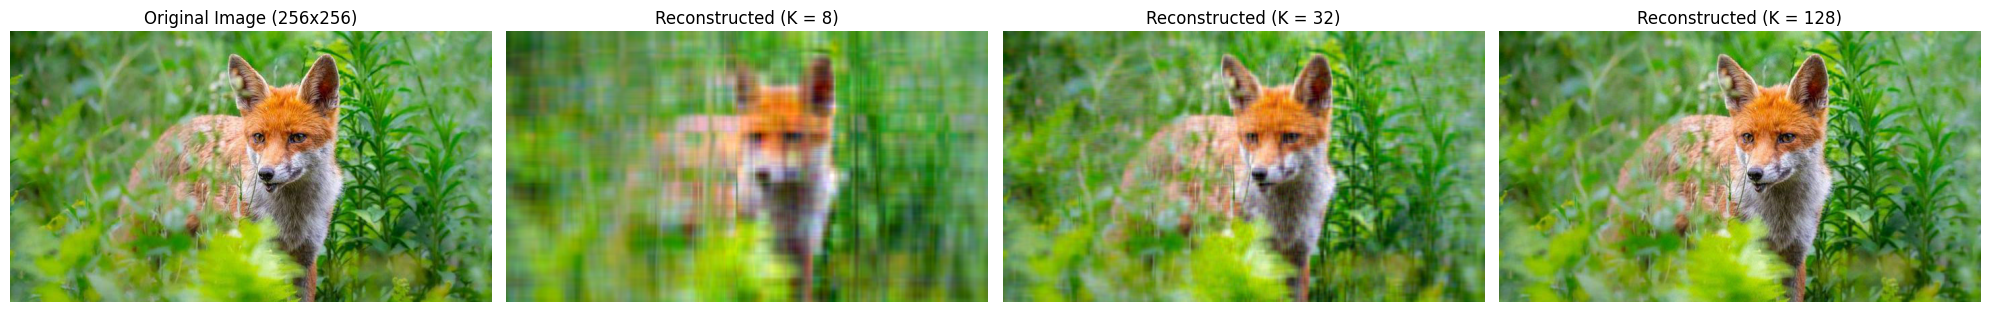

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img)
axes[0].set_title("Original Image (256x256)")
axes[0].axis('off')

axes[1].imshow(img_low)
axes[1].set_title(f"Reconstructed (K = {K_low})")
axes[1].axis('off')

axes[2].imshow(img_suitable)
axes[2].set_title(f"Reconstructed (K = {K_suitable})")
axes[2].axis('off')

axes[3].imshow(img_high)
axes[3].set_title(f"Reconstructed (K = {K_high})")
axes[3].axis('off')

plt.tight_layout()
plt.show()

## Exercise Questions

**What's the relationship between the number of components ($K$) and the compression
rate?**

It's an inverse relationship with file size: the smaller $K$ is (e.g. $K=8$), the fewer
vectors and dimensions need to be stored, so the compression rate is very high — but
reconstruction error increases and the image looks blurry or blocky. The larger $K$ is
(e.g. $K=128$), the lower the compression rate, but image detail is preserved with much
higher fidelity.

**Is PCA better than JPEG for image compression?**

No, JPEG is significantly better. JPEG uses the Discrete Cosine Transform (DCT) combined
with Huffman coding, specifically optimized around the frequencies the human visual
system is most sensitive to.

PCA, by contrast, requires storing both the compressed (transformed) data *and* the
matrix of eigenvectors (principal components) needed to reconstruct the image — and that
component matrix alone carries substantial overhead, which largely defeats the purpose of
compression on real images. PCA is a general-purpose dimensionality-reduction technique
for data, not a specialized image compression format.
